# ClearBank — Análise Financeira com Python

Notebook do desafio final: leitura e validação do histórico de transações (`transacoes.csv`),
geração de métricas financeiras mensais, identificação de transações suspeitas, relatório
formatado no terminal e exportação para `relatorio.json`.

## Instruções

1. O arquivo **`transacoes.csv`** deve estar na mesma pasta do notebook, com as colunas
   `id, data, cliente_id, tipo, valor, descricao, categoria`.
2. Para testes, o arquivo deve conter **pelo menos 15 registros válidos** distribuídos em
   **3 ou mais meses**, **5 registros inválidos** e **2 transações acima de R$ 10.000,00**.
   O arquivo usado aqui tem 17 válidas (4 meses), 9 inválidas (incluindo 1 id duplicado) e 3 suspeitas.
3. Se o arquivo não existir (ex.: no Colab), a célula *Preparação dos dados* o cria com os dados de teste.
4. Execute as células **em ordem** (*Runtime → Run all* no Colab ou *Run All* no Jupyter).
   Cada etapa tem um teste rápido no final; a **Célula de Execução Principal** roda tudo junto.

> Requisitos: Python 3.10+. Partes opcionais usam `pandas` e `matplotlib` (`pip install pandas matplotlib`).

## 1. Imports e constantes

In [2]:
import csv
import json
import os
from datetime import date, datetime

ARQUIVO_CSV = "transacoes.csv"
ARQUIVO_JSON = "relatorio.json"
LIMITE_SUSPEITO = 10000.00
TIPOS_VALIDOS = ("credito", "debito")
FORMATO_DATA = "%Y-%m-%d"
FORMATO_MES = "%Y-%m"
SEPARADOR = "=" * 5

## 2. Preparação dos dados

Cria o `transacoes.csv` de teste **somente se ele ainda não existir** — assim um arquivo
criado manualmente nunca é sobrescrito.

In [6]:
CSV_DE_TESTE = """id,data,cliente_id,tipo,valor,descricao,categoria
1,2026-01-05,CLI001,credito,3500.00,Salário janeiro,salario
2,2026-01-12,CLI002,debito,180.50,Supermercado,compra
3,2026-01-20,CLI001,debito,abc,Erro de sistema,compra
4,2026-01-22,CLI004,credito,12500.00,Venda de veículo,transferencia
5,2026-01-28,CLI002,debito,1200.00,Aluguel,conta
6,2026-02-03,,debito,200.00,Sem cliente,transferencia
7,2026-02-05,CLI002,credito,4200.00,Salário fevereiro,salario
8,2026-02-14,CLI003,credito,15000.00,Transferência suspeita,transferencia
9,2026-02-18,CLI002,debito,320.00,Conta de luz,conta
10,2026/02/20,CLI001,debito,89.90,Data mal formatada,compra
11,2026-02-25,CLI001,debito,450.75,Farmácia,compra
12,2026-03-01,CLI001,credito,3500.00,Salário março,salario
13,2026-03-10,CLI003,debito,99.90,Streaming,assinatura
14,2026-03-12,CLI004,estorno,75.00,Tipo inválido,compra
15,2026-03-15,CLI004,debito,-50.00,Valor negativo,compra
16,2026-03-18,CLI002,debito,640.30,Mercado mensal,compra
17,2026-03-22,CLI003,debito,10850.00,Pagamento imóvel,transferencia
18,2026-13-01,CLI001,credito,500.00,Mês inexistente,transferencia
19,2026-04-01,CLI001,credito,3500.00,Salário abril,salario
20,2026-04-04,CLI002,debito,0,Valor zerado,compra
21,2026-04-08,CLI003,debito,59.90,Academia,assinatura
22,2026-04-15,CLI004,credito,2750.00,Freelance,transferencia
abc,2026-04-18,CLI002,debito,35.00,ID inválido,compra
23,2026-04-22,CLI002,debito,215.40,Restaurante,compra
23,2026-04-22,CLI002,debito,215.40,Restaurante,compra
24,2026-04-28,CLI001,debito,980.00,Cartão de crédito,conta
"""

if not os.path.exists(ARQUIVO_CSV):
    with open(ARQUIVO_CSV, "w", encoding="utf-8", newline="") as arquivo:
        arquivo.write(CSV_DE_TESTE)
    print(f"Arquivo '{ARQUIVO_CSV}' criado com os dados de teste.")
else:
    print(f"Arquivo '{ARQUIVO_CSV}' já existe — usando o arquivo atual.")

Arquivo 'transacoes.csv' criado com os dados de teste.


## 3. Leitura do CSV

Usa o módulo nativo `csv` com `csv.DictReader`. Se o arquivo não existir, o erro
`FileNotFoundError` é tratado e a função devolve uma lista vazia.

In [8]:
def ler_transacoes(caminho=ARQUIVO_CSV):
    """Lê o CSV e retorna a lista de transações brutas (dicionários de texto)."""
    try:
        with open(caminho, encoding="utf-8", newline="") as arquivo:
            return list(csv.DictReader(arquivo))
    except FileNotFoundError:
        print(f"Erro: o arquivo '{caminho}' não foi encontrado.")
        return []


# Teste rápido
brutas = ler_transacoes()
print(f"Linhas lidas: {len(brutas)}")
print("Primeira linha:", brutas[0])
print("Arquivo inexistente:", ler_transacoes("nao_existe.csv"))

Linhas lidas: 26
Primeira linha: {'id': '1', 'data': '2026-01-05', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': '3500.00', 'descricao': 'Salário janeiro', 'categoria': 'salario'}
Erro: o arquivo 'nao_existe.csv' não foi encontrado.
Arquivo inexistente: []


## 4. Validação e limpeza

Cada campo tem sua própria função de validação, que devolve o valor convertido ou `None`.
`validar_transacao()` combina essas funções e devolve o registro limpo (ou `None`).
Linhas inválidas e ids duplicados são descartados sem interromper o processamento.

In [9]:
def validar_id(texto):
    """Converte o id para inteiro; retorna None se vazio ou não numérico."""
    try:
        return int(texto)
    except (ValueError, TypeError):
        return None


def converter_valor(texto):
    """Converte o valor para float; retorna None se não numérico ou <= 0."""
    try:
        valor = float(texto)
    except (ValueError, TypeError):
        return None
    return valor if valor > 0 else None


def converter_data(texto):
    """Converte 'AAAA-MM-DD' em datetime; retorna None se o formato for inválido."""
    try:
        return datetime.strptime(texto, FORMATO_DATA)
    except (ValueError, TypeError):
        return None


def validar_transacao(linha):
    """Valida uma linha do CSV e retorna o registro limpo, ou None se for inválida."""
    campos = {chave: (valor or "").strip() for chave, valor in linha.items() if chave}
    id_transacao = validar_id(campos.get("id"))
    data = converter_data(campos.get("data"))
    valor = converter_valor(campos.get("valor"))
    tipo = campos.get("tipo", "").lower()
    cliente_id = campos.get("cliente_id", "")

    if None in (id_transacao, data, valor) or not cliente_id or tipo not in TIPOS_VALIDOS:
        return None
    return {
        "id": id_transacao,
        "data": data,
        "mes": data.strftime(FORMATO_MES),
        "cliente_id": cliente_id,
        "tipo": tipo,
        "valor": valor,
        "descricao": campos.get("descricao", ""),
        "categoria": campos.get("categoria", ""),
    }


def limpar_transacoes(brutas):
    """Valida todas as linhas, descarta inválidas e duplicadas e exibe o resumo da limpeza."""
    validas, ids_vistos = [], set()
    for linha in brutas:
        transacao = validar_transacao(linha)
        if transacao is None or transacao["id"] in ids_vistos:
            continue
        ids_vistos.add(transacao["id"])
        validas.append(transacao)

    invalidas = len(brutas) - len(validas)
    print(f"Total de linhas lidas: {len(brutas)}")
    print(f"Linhas válidas: {len(validas)}")
    print(f"Linhas inválidas: {invalidas}")
    return validas, invalidas


# Teste rápido
print(validar_id("12"), validar_id("abc"), validar_id(""))
print(converter_valor("180.50"), converter_valor("abc"), converter_valor("-50"), converter_valor("0"))
print(converter_data("2026-02-14"), converter_data("2026/02/20"), converter_data("2026-13-01"))
print(validar_transacao({"id": "4", "data": "2026-02-03", "cliente_id": "", "tipo": "debito",
                         "valor": "200.00", "descricao": "Sem cliente", "categoria": "transferencia"}))
print()
validas, invalidas = limpar_transacoes(brutas)

12 None None
180.5 None None None
2026-02-14 00:00:00 None None
None

Total de linhas lidas: 26
Linhas válidas: 17
Linhas inválidas: 9


## 5. Datas e período analisado

As datas já foram convertidas com `strptime` e o mês (`AAAA-MM`) foi extraído com `strftime`.
Aqui calculamos a data mais antiga, a mais recente e quantos dias se passaram entre elas.

In [10]:
def calcular_periodo(transacoes):
    """Retorna a data mais antiga, a mais recente e os dias entre elas."""
    datas = [transacao["data"] for transacao in transacoes]
    if not datas:
        return None
    inicio, fim = min(datas), max(datas)
    return {
        "inicio": inicio.strftime(FORMATO_DATA),
        "fim": fim.strftime(FORMATO_DATA),
        "dias": (fim - inicio).days,
    }


# Teste rápido
print("Meses encontrados:", sorted({t["mes"] for t in validas}))
print("Período:", calcular_periodo(validas))

Meses encontrados: ['2026-01', '2026-02', '2026-03', '2026-04']
Período: {'inicio': '2026-01-05', 'fim': '2026-04-28', 'dias': 113}


## 6. Agrupamento mensal, métricas e transações suspeitas

Para cada mês: quantidade, total de crédito, total de débito, saldo, média,
maior e menor transação. Transações acima de `LIMITE_SUSPEITO` são sinalizadas.

In [12]:
def agrupar_por_mes(transacoes):
    """Agrupa as transações em um dicionário {mes: [transações]}."""
    grupos = {}
    for transacao in transacoes:
        grupos.setdefault(transacao["mes"], []).append(transacao)
    return grupos


def resumir_transacao(transacao):
    """Versão reduzida de uma transação, usada no relatório."""
    return {"id": transacao["id"], "valor": round(transacao["valor"], 2)}


def calcular_metricas_mes(transacoes):
    """Calcula as métricas de um mês a partir de suas transações."""
    total_credito = sum(t["valor"] for t in transacoes if t["tipo"] == "credito")
    total_debito = sum(t["valor"] for t in transacoes if t["tipo"] == "debito")
    maior = max(transacoes, key=lambda t: t["valor"])
    menor = min(transacoes, key=lambda t: t["valor"])
    return {
        "quantidade": len(transacoes),
        "total_credito": round(total_credito, 2),
        "total_debito": round(total_debito, 2),
        "saldo": round(total_credito - total_debito, 2),
        "media": round(sum(t["valor"] for t in transacoes) / len(transacoes), 2),
        "maior_valor": resumir_transacao(maior),
        "menor_valor": resumir_transacao(menor),
    }


def identificar_suspeitas(transacoes, limite=LIMITE_SUSPEITO):
    """Retorna as transações com valor acima do limite."""
    return [
        {
            "id": t["id"],
            "cliente_id": t["cliente_id"],
            "data": t["data"].strftime(FORMATO_DATA),
            "valor": round(t["valor"], 2),
        }
        for t in transacoes
        if t["valor"] > limite
    ]


def gerar_relatorio(validas, invalidas):
    """Agrupa os dados e monta o dicionário completo do relatório."""
    grupos = agrupar_por_mes(validas)
    return {
        "gerado_em": date.today().isoformat(),
        "total_transacoes_validas": len(validas),
        "total_transacoes_invalidas": invalidas,
        "periodo": calcular_periodo(validas),
        "resumo_mensal": {mes: calcular_metricas_mes(grupos[mes]) for mes in sorted(grupos)},
        "transacoes_suspeitas": identificar_suspeitas(validas),
    }


# Teste rápido
relatorio = gerar_relatorio(validas, invalidas)
print("Métricas de 2026-01:", relatorio["resumo_mensal"]["2026-01"])
print("Suspeitas:", relatorio["transacoes_suspeitas"])

Métricas de 2026-01: {'quantidade': 4, 'total_credito': 16000.0, 'total_debito': 1380.5, 'saldo': 14619.5, 'media': 4345.12, 'maior_valor': {'id': 4, 'valor': 12500.0}, 'menor_valor': {'id': 2, 'valor': 180.5}}
Suspeitas: [{'id': 4, 'cliente_id': 'CLI004', 'data': '2026-01-22', 'valor': 12500.0}, {'id': 8, 'cliente_id': 'CLI003', 'data': '2026-02-14', 'valor': 15000.0}, {'id': 17, 'cliente_id': 'CLI003', 'data': '2026-03-22', 'valor': 10850.0}]


## 7. Exportação para JSON

In [13]:
def salvar_json(relatorio, caminho=ARQUIVO_JSON):
    """Salva o relatório em JSON com acentos preservados e indentação."""
    try:
        with open(caminho, "w", encoding="utf-8") as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2)
    except OSError as erro:
        print(f"Erro ao salvar '{caminho}': {erro}")
        return False
    print(f"Relatório salvo em '{caminho}'.")
    return True


# Teste rápido
salvar_json(relatorio)
with open(ARQUIVO_JSON, encoding="utf-8") as arquivo:
    print(arquivo.read()[:400], "...")

Relatório salvo em 'relatorio.json'.
{
  "gerado_em": "2026-10-15",
  "total_transacoes_validas": 17,
  "total_transacoes_invalidas": 9,
  "periodo": {
    "inicio": "2026-01-05",
    "fim": "2026-04-28",
    "dias": 113
  },
  "resumo_mensal": {
    "2026-01": {
      "quantidade": 4,
      "total_credito": 16000.0,
      "total_debito": 1380.5,
      "saldo": 14619.5,
      "media": 4345.12,
      "maior_valor": {
        "id": 4,
 ...


## 8. Exibição formatada no terminal

In [14]:
def formatar_moeda(valor):
    """Formata um número no padrão monetário brasileiro: R$ 1.234,56."""
    texto = f"{abs(valor):,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    sinal = "-" if valor < 0 else ""
    return f"{sinal}R$ {texto}"


def titulo(texto):
    """Imprime o título de uma seção entre separadores."""
    print(f"\n{SEPARADOR} {texto} {SEPARADOR}\n")


def exibir_metricas_mes(mes, metricas):
    """Imprime o bloco de métricas de um mês."""
    print(f"Mês: {mes}")
    print(f"  Transações: {metricas['quantidade']}")
    print(f"  Total crédito: {formatar_moeda(metricas['total_credito'])}")
    print(f"  Total débito:  {formatar_moeda(metricas['total_debito'])}")
    print(f"  Saldo:         {formatar_moeda(metricas['saldo'])}")
    print(f"  Média:         {formatar_moeda(metricas['media'])}")
    print(f"  Maior valor:   {formatar_moeda(metricas['maior_valor']['valor'])} (ID {metricas['maior_valor']['id']})")
    print(f"  Menor valor:   {formatar_moeda(metricas['menor_valor']['valor'])} (ID {metricas['menor_valor']['id']})")
    print()


def exibir_suspeitas(suspeitas):
    """Imprime a lista de transações suspeitas."""
    titulo("TRANSAÇÕES SUSPEITAS")
    if not suspeitas:
        print("Nenhuma transação suspeita encontrada.")
    for t in suspeitas:
        print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | Data: {t['data']} | Valor: {formatar_moeda(t['valor'])}")


def exibir_relatorio(relatorio):
    """Formata e imprime o relatório completo."""
    titulo("CLEARBANK — RESUMO GERAL")
    periodo = relatorio["periodo"]
    if periodo:
        print(f"Período analisado: {periodo['inicio']} → {periodo['fim']} ({periodo['dias']} dias)")
    print(f"Transações válidas:   {relatorio['total_transacoes_validas']}")
    print(f"Transações inválidas: {relatorio['total_transacoes_invalidas']}")

    titulo("RELATÓRIO MENSAL")
    for mes, metricas in relatorio["resumo_mensal"].items():
        exibir_metricas_mes(mes, metricas)
    exibir_suspeitas(relatorio["transacoes_suspeitas"])


# Teste rápido
print(formatar_moeda(3319.5), "|", formatar_moeda(15000), "|", formatar_moeda(-8090.2))
exibir_suspeitas([])

R$ 3.319,50 | R$ 15.000,00 | -R$ 8.090,20

===== TRANSAÇÕES SUSPEITAS =====

Nenhuma transação suspeita encontrada.


## 9. Célula de Execução Principal

Executa todo o fluxo: leitura → validação → métricas → JSON → relatório.

In [15]:
def main():
    """Executa a análise completa das transações."""
    titulo("LIMPEZA DOS DADOS")
    brutas = ler_transacoes(ARQUIVO_CSV)
    if not brutas:
        print("Nenhuma transação para processar.")
        return None
    validas, invalidas = limpar_transacoes(brutas)
    relatorio = gerar_relatorio(validas, invalidas)
    exibir_relatorio(relatorio)
    print()
    salvar_json(relatorio, ARQUIVO_JSON)
    return relatorio


relatorio = main()


===== LIMPEZA DOS DADOS =====

Total de linhas lidas: 26
Linhas válidas: 17
Linhas inválidas: 9

===== CLEARBANK — RESUMO GERAL =====

Período analisado: 2026-01-05 → 2026-04-28 (113 dias)
Transações válidas:   17
Transações inválidas: 9

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações: 4
  Total crédito: R$ 16.000,00
  Total débito:  R$ 1.380,50
  Saldo:         R$ 14.619,50
  Média:         R$ 4.345,12
  Maior valor:   R$ 12.500,00 (ID 4)
  Menor valor:   R$ 180,50 (ID 2)

Mês: 2026-02
  Transações: 4
  Total crédito: R$ 19.200,00
  Total débito:  R$ 770,75
  Saldo:         R$ 18.429,25
  Média:         R$ 4.992,69
  Maior valor:   R$ 15.000,00 (ID 8)
  Menor valor:   R$ 320,00 (ID 9)

Mês: 2026-03
  Transações: 4
  Total crédito: R$ 3.500,00
  Total débito:  R$ 11.590,20
  Saldo:         -R$ 8.090,20
  Média:         R$ 3.772,55
  Maior valor:   R$ 10.850,00 (ID 17)
  Menor valor:   R$ 99,90 (ID 13)

Mês: 2026-04
  Transações: 5
  Total crédito: R$ 6.250,00
  Total débito: 

## 10. (Opcional) Análise com pandas

A versão alternativa está em `analise_pandas.py`: usa `pd.read_csv()`, aplica as mesmas regras de
validação, agrupa por mês com `groupby` e compara cada métrica com o `relatorio.json` gerado acima.

In [16]:
%run analise_pandas.py

Linhas lidas: 26 | Válidas: 17 | Inválidas: 9

         quantidade  total_credito  total_debito     saldo    media  maior_valor  menor_valor
mes                                                                                          
2026-01           4        16000.0       1380.50  14619.50  4345.12      12500.0        180.5
2026-02           4        19200.0        770.75  18429.25  4992.69      15000.0        320.0
2026-03           4         3500.0      11590.20  -8090.20  3772.55      10850.0         99.9
2026-04           5         6250.0       1255.30   4994.70  1501.06       3500.0         59.9

Resultados idênticos aos da solução nativa ✔


## 11. (Opcional) Visualização com matplotlib

Barras agrupadas de crédito e débito por mês, com o saldo mensal marcado no mesmo eixo (R$).
O gráfico é salvo em `grafico.png`.

Gráfico salvo em 'grafico.png'.


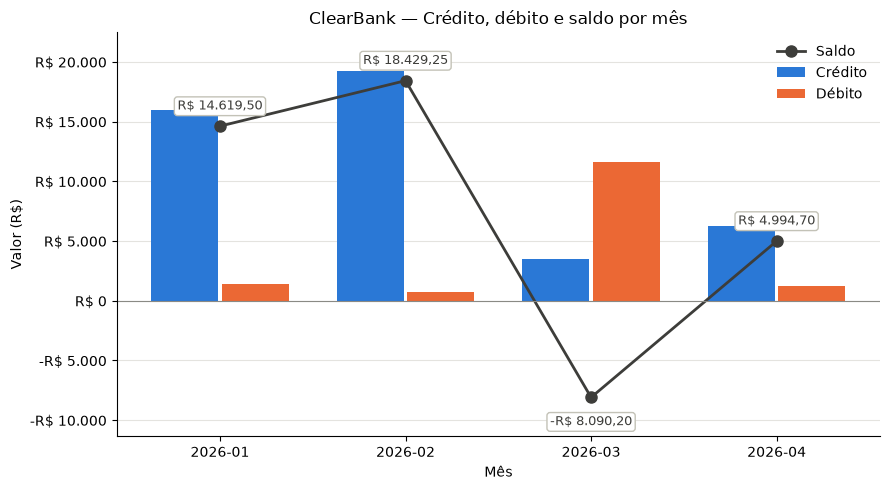

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


def gerar_grafico(relatorio, caminho="grafico.png"):
    """Gera o gráfico de crédito, débito e saldo por mês e salva como imagem."""
    meses = list(relatorio["resumo_mensal"])
    resumo = relatorio["resumo_mensal"]
    creditos = [resumo[m]["total_credito"] for m in meses]
    debitos = [resumo[m]["total_debito"] for m in meses]
    saldos = [resumo[m]["saldo"] for m in meses]
    posicoes = range(len(meses))
    largura = 0.36

    fig, eixo = plt.subplots(figsize=(9, 5))
    eixo.bar([p - largura / 2 - 0.01 for p in posicoes], creditos, largura, label="Crédito", color="#2a78d6")
    eixo.bar([p + largura / 2 + 0.01 for p in posicoes], debitos, largura, label="Débito", color="#eb6834")
    eixo.plot(posicoes, saldos, color="#3d3d3a", linewidth=2, marker="o", markersize=8, label="Saldo")
    for p, saldo in zip(posicoes, saldos):
        eixo.annotate(formatar_moeda(saldo), (p, saldo), textcoords="offset points",
                      xytext=(0, 12 if saldo >= 0 else -20), ha="center", fontsize=9, color="#3d3d3a",
                      bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "#c3c2b7"})

    eixo.set_title("ClearBank — Crédito, débito e saldo por mês")
    eixo.set_xlabel("Mês")
    eixo.set_ylabel("Valor (R$)")
    eixo.set_xticks(list(posicoes), meses)
    eixo.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formatar_moeda(v).replace(",00", "")))
    eixo.margins(y=0.12)
    eixo.axhline(0,color="#8a8a85", linewidth=0.8)
    eixo.grid(axis="y", color="#e4e3df", linewidth=0.8)
    eixo.set_axisbelow(True)
    eixo.spines[["top", "right"]].set_visible(False)
    eixo.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(caminho, dpi=150)
    print(f"Gráfico salvo em '{caminho}'.")
    plt.show()


gerar_grafico(relatorio)